In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [7]:
from google.colab import files
uploaded=files.upload()

Saving agaricus-lepiota.csv to agaricus-lepiota (1).csv


In [13]:
df=pd.read_csv("agaricus-lepiota.csv",header=None)
df

,0,1,2,3,4,5,6,7,8,9,...,13,14,15,16,17,18,19,20,21,22
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8119,e,k,s,n,f,n,a,c,b,y,...,s,o,o,p,o,o,p,b,c,l
8120,e,x,s,n,f,n,a,c,b,y,...,s,o,o,p,n,o,p,b,v,l
8121,e,f,s,n,f,n,a,c,b,n,...,s,o,o,p,o,o,p,b,c,l
8122,p,k,y,n,f,y,f,c,n,b,...,k,w,w,p,w,o,e,w,v,l


In [9]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   0       8124 non-null   object
 1   1       8124 non-null   object
 2   2       8124 non-null   object
 3   3       8124 non-null   object
 4   4       8124 non-null   object
 5   5       8124 non-null   object
 6   6       8124 non-null   object
 7   7       8124 non-null   object
 8   8       8124 non-null   object
 9   9       8124 non-null   object
 10  10      8124 non-null   object
 11  11      8124 non-null   object
 12  12      8124 non-null   object
 13  13      8124 non-null   object
 14  14      8124 non-null   object
 15  15      8124 non-null   object
 16  16      8124 non-null   object
 17  17      8124 non-null   object
 18  18      8124 non-null   object
 19  19      8124 non-null   object
 20  20      8124 non-null   object
 21  21      8124 non-null   object
 22  22      8124 non-null   

In [11]:
df.head()

,p,x,s,n,t,p.1,f,c,n.1,k,...,s.2,w,w.1,p.2,w.2,o,p.3,k.1,s.3,u
0,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
1,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
2,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
3,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g
4,e,x,y,y,t,a,f,c,b,n,...,s,w,w,p,w,o,p,k,n,g


In [47]:
print(df.columns)

Index(['p', 'x', 's', 'n', 't', 'p.1', 'f', 'c', 'n.1', 'k', 'e', 'e.1', 's.1',
       's.2', 'w', 'w.1', 'p.2', 'w.2', 'o', 'p.3', 'k.1', 's.3', 'u'],
      dtype='object')


In [48]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
p      0
x      0
s      0
n      0
t      0
p.1    0
f      0
c      0
n.1    0
k      0
e      0
e.1    0
s.1    0
s.2    0
w      0
w.1    0
p.2    0
w.2    0
o      0
p.3    0
k.1    0
s.3    0
u      0
dtype: int64


In [51]:
print("Total Duplicate Rows:")
print(df.duplicated().sum())

Total Duplicate Rows:
0


In [65]:
print(df.iloc[:,0].value_counts())

p
e    4208
p    3915
Name: count, dtype: int64


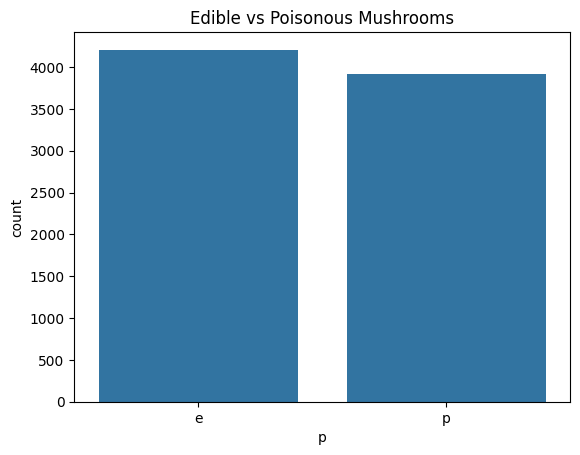

In [52]:
sns.countplot(x=df.iloc[:, 0])
plt.title("Edible vs Poisonous Mushrooms")
plt.show()

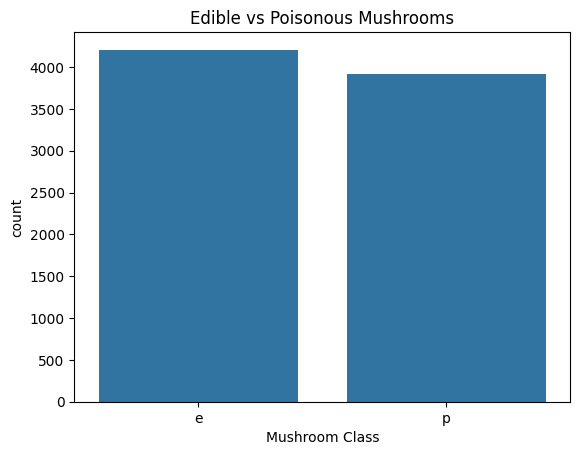

In [55]:
sns.countplot(x=df.iloc[:, 0])
plt.title("Edible vs Poisonous Mushrooms")
plt.xlabel("Mushroom Class")
plt.ylabel("count")
plt.show()

Text(0, 0.5, 'count')

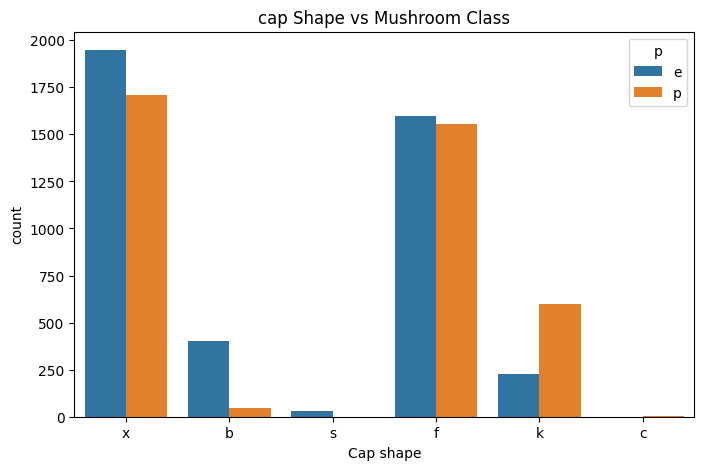

In [71]:
plt.figure(figsize=(8,5))
sns.countplot(x=df.iloc[:,1],hue=df.iloc[:,0])
plt.title("cap Shape vs Mushroom Class")
plt.xlabel("Cap shape")
plt.ylabel("count")

In [26]:
df = df.replace("?", np.nan)
df = df.fillna(df.mode().iloc[0])

In [27]:
X = df.iloc[:, 1:]
y = df.iloc[:, 0]

In [28]:
X = pd.get_dummies(X)

In [29]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [30]:
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report


In [31]:
heatmap_data=pd.crosstab(df.iloc[:,1],df.iloc[:,0])
print(heatmap_data)

0     e     p
1            
b   404    48
c     0     4
f  1596  1556
k   228   600
s    32     0
x  1948  1708


Text(20.72222222222222, 0.5, 'Cap Shape')

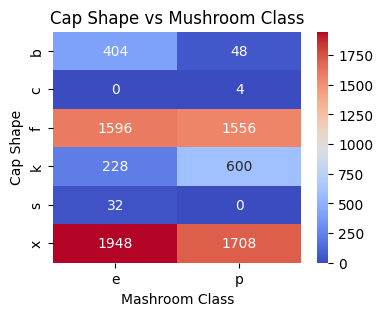

In [32]:
plt.figure(figsize=(4,3))
sns.heatmap(heatmap_data,annot=True,fmt='d',cmap='coolwarm')
plt.title("Cap Shape vs Mushroom Class")
plt.xlabel("Mashroom Class")
plt.ylabel("Cap Shape")

In [34]:
nb=GaussianNB()
nb.fit(X_train,y_train)

nb_pred=nb.predict(X_test)

print("Naive Bayes Accuracy:",accuracy_score(y_test,nb_pred))
print(classification_report(y_test,nb_pred))

Naive Bayes Accuracy: 0.9569230769230769
              precision    recall  f1-score   support

           e       1.00      0.92      0.96       842
           p       0.92      1.00      0.96       783

    accuracy                           0.96      1625
   macro avg       0.96      0.96      0.96      1625
weighted avg       0.96      0.96      0.96      1625



In [35]:
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

dt_pred = dt.predict(X_test)

print("Decision Tree Accuracy:", accuracy_score(y_test, dt_pred))
print(classification_report(y_test, dt_pred))

Decision Tree Accuracy: 1.0
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       842
           p       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



In [36]:
rf = RandomForestClassifier(random_state=42)
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)

print("Random Forest Accuracy:", accuracy_score(y_test, rf_pred))
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 1.0
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       842
           p       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625



In [37]:
results = pd.DataFrame({
    "Model": ["Naive Bayes", "Decision Tree", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, nb_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred)
    ]
})

print(results)

           Model  Accuracy
0    Naive Bayes  0.956923
1  Decision Tree  1.000000
2  Random Forest  1.000000


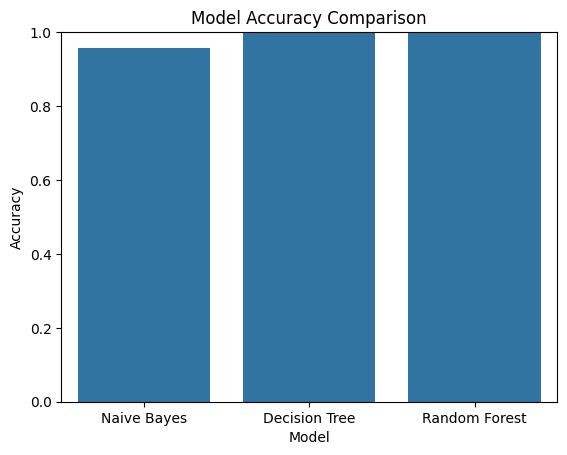

In [38]:
sns.barplot(x="Model", y="Accuracy", data=results)
plt.title("Model Accuracy Comparison")
plt.ylim(0, 1)
plt.show()

In [39]:
print("Naive Bayes Classification Report:")
print(classification_report(y_test, nb_pred))
print("\nDecision Tree Classification Report:")
print(classification_report(y_test, dt_pred))
print("\nRandom Forest Classification Report:")
print(classification_report(y_test, rf_pred))

Naive Bayes Classification Report:
              precision    recall  f1-score   support

           e       1.00      0.92      0.96       842
           p       0.92      1.00      0.96       783

    accuracy                           0.96      1625
   macro avg       0.96      0.96      0.96      1625
weighted avg       0.96      0.96      0.96      1625


Decision Tree Classification Report:
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       842
           p       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg       1.00      1.00      1.00      1625
weighted avg       1.00      1.00      1.00      1625


Random Forest Classification Report:
              precision    recall  f1-score   support

           e       1.00      1.00      1.00       842
           p       1.00      1.00      1.00       783

    accuracy                           1.00      1625
   macro avg     

In [41]:
from sklearn.metrics import confusion_matrix

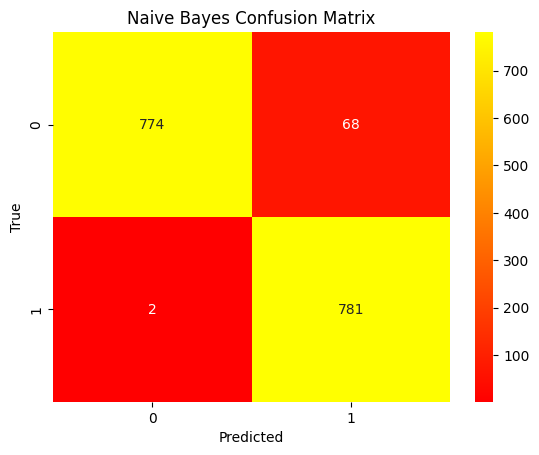

In [42]:
cm=confusion_matrix(y_test,nb_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='autumn')
plt.title("Naive Bayes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.show()

In [48]:
importances = dt.feature_importances_
feature_names = X_train.columns
feature_df=pd.DataFrame({"Feature":feature_names,"Importance":importances})
feature_df=feature_df.sort_values(by="Importance",ascending=False)
print(feature_df.head(10))

   Feature  Importance
27     5_n    0.617790
51    11_b    0.182243
35     8_b    0.087261
99    20_r    0.035830
22     5_a    0.022530
25     5_l    0.021906
26     5_m    0.015878
62    13_y    0.013490
7      2_g    0.001844
1      1_c    0.000616


Text(0.5, 1.0, 'Top 10 Most Important Mushroom Features ')

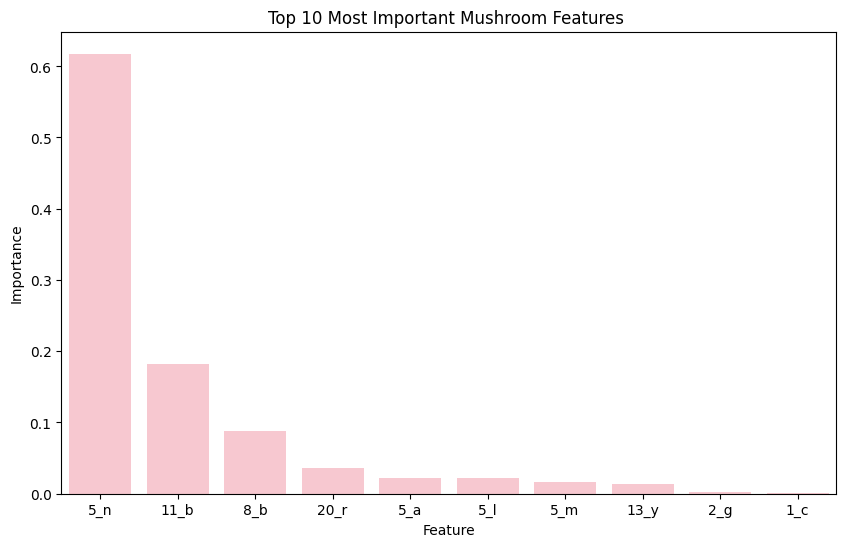

In [51]:
plt.figure(figsize=(10,6))
sns.barplot(x="Feature",y="Importance",data=feature_df.head(10),color='pink')
plt.title("Top 10 Most Important Mushroom Features ")